<a href="https://colab.research.google.com/github/Gunjannn07/FlyRank1/blob/main/work/notebooks/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Gunjannn07/FlyRank1/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*



The project investigates whether safe search visibility, content, and engagement signals can identify content that may deserve CTR or engagement review.

The practical decision is **which content should be reviewed first**. A useful output is a ranked queue with an opportunity score, transparent reason codes, and a suggested action.

This project does **not** attempt to discover Google's ranking algorithm or prove that a content refresh causes better performance.

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

- **Starting dataset:** `data/raw/content_refresh_anonymized.csv`
- **Previously inspected warehouse table:** `fact_content_daily_performance`
- **Previously inspected date window:** 2026-03-01 to 2026-03-31
- **W03 warehouse scale:** 78,835,655 total rows; 9,841,378 rows for March 2026.
- **March data availability :** 3,611,061 rows with GSC data and 413,966 rows with GA4 data.
- **Previously used features/fields:** `search_volume`, `content_type`, `ctr`, `avg_position`, `engagement_rate`, `scroll_rate`, `ai_traffic_pct`, `position_tier`, `trend_direction`, `trend_pct`, `impression_tier`, and `char_count_tier`.


For the public paper, I excluded client names, domains, URLs, private queries, credentials, and raw identifying exports. Use anonymized identifiers only when permitted by the dataset rules.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

DATA_PATH = Path("data/raw/content_refresh_anonymized.csv")

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
    print("Loaded:", DATA_PATH)
    print("Shape:", df.shape)
    display(df.head())
else:
    print(f"Dataset not found at {DATA_PATH.resolve()}")
    print("Run this notebook from the repository root, or update DATA_PATH to the dataset location.")

Dataset not found at /content/data/raw/content_refresh_anonymized.csv
Run this notebook from the repository root, or update DATA_PATH to the dataset location.


In [2]:

import os
import sys
import subprocess

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/flyrank-bih/flyrank-ml-internship-starter"
REPO_DIR = "flyrank-ml-internship-starter"

if IN_COLAB:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(
            ["git", "clone", "--depth", "1", REPO_URL, REPO_DIR],
            check=True
        )

    os.chdir(REPO_DIR)

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"],
        check=True
    )

import pandas as pd
import numpy as np

df = pd.read_csv("data/raw/content_refresh_anonymized.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (30000, 44)


,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9
3,content_331d6c4de07b,client_19581e27de,10.0,0.00,LOW,0.00,keyword article,commercial,NaN,NaN,...,NaN,0.49,6.2,1.28,3.45,0.0,good,page_1,stable,-13.8
4,content_d99b7a2d90ca,client_3fdba35f04,0.0,0.00,LOW,0.00,keyword article,informational,2803.0,17469.0,...,15000-25000,0.13,44.0,0.00,24.29,0.0,good,page_3_5,down,-34.7


In [3]:
if "df" in globals():
    print("Columns:")
    print(df.columns.tolist())
    print("\\nMissing values (top 20):")
    display(df.isna().sum().sort_values(ascending=False).head(20).to_frame("missing_count"))
    print("\\nDuplicate rows:", int(df.duplicated().sum()))
    for col in ["content_id", "client_id"]:
        if col in df.columns:
            print(f"Unique {col}:", df[col].nunique(dropna=True))

Columns:
['content_id', 'client_id', 'search_volume', 'competition', 'competition_level', 'cpc', 'content_type', 'main_intent', 'word_count', 'char_count', 'provider_used', 'model_used', 'impressions_90d', 'clicks_90d', 'pageviews_90d', 'sessions_90d', 'users_90d', 'engaged_sessions_90d', 'ai_sessions_90d', 'scroll_events_90d', 'days_with_impressions', 'days_with_sessions', 'impressions_last_30d', 'clicks_last_30d', 'sessions_last_30d', 'impressions_prev_30d', 'clicks_prev_30d', 'sessions_prev_30d', 'content_age_days', 'age_tier', 'age_tier_order', 'days_since_last_update', 'freshness_tier', 'word_count_tier', 'char_count_tier', 'ctr', 'avg_position', 'engagement_rate', 'scroll_rate', 'ai_traffic_pct', 'impression_tier', 'position_tier', 'trend_direction', 'trend_pct']
\nMissing values (top 20):


,missing_count
provider_used,21438
word_count,7699
char_count,7699
word_count_tier,7699
char_count_tier,7699
model_used,5733
trend_pct,3388
competition_level,2610
search_volume,2468
cpc,2468


\nDuplicate rows: 0
Unique content_id: 30000
Unique client_id: 32


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*



##### This capstone uses a **CTR / Engagement Opportunity Scoring** approach to identify content that may benefit from further review.

1. **Feature Engineering:** Use available search visibility, average position, CTR, content type, and engagement signals to characterize content performance.
2. **Opportunity Scoring:** Compare observed CTR with expected CTR for comparable position groups and consider search visibility to prioritize potential opportunities.
3. **Model Evaluation:** Compare a baseline with a Decision Tree model, using the same evaluation metric and held-out data. The initial W05 experiment used a client-grouped split; further validation and leakage checks are required before finalizing the results.
4. **Decision Support:** Generate a ranked content-review queue with reason codes and suggested actions to help prioritize editorial effort.

The scores indicate **review priorities, not guaranteed CTR improvements**. Results are observational and do not establish causal effects or reveal Google's ranking algorithm.

In [4]:
# Audit the target and available features before fitting anything.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

assert "df" in globals(), "Run the data-loading cell first."
assert "ctr" in df.columns, "The dataset must contain the target column 'ctr'."

target = "ctr"
numeric_candidates = [
    "search_volume", "avg_position", "competition", "cpc",
    "word_count", "char_count"
]
categorical_candidates = ["content_type", "main_intent"]

numeric_features = [c for c in numeric_candidates if c in df.columns]
categorical_features = [c for c in categorical_candidates if c in df.columns]
feature_cols = numeric_features + categorical_features

audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
}).sort_values("missing_pct", ascending=False)

print("Rows, columns:", df.shape)
print("Candidate numeric features:", numeric_features)
print("Candidate categorical features:", categorical_features)
display(audit)

df[target] = pd.to_numeric(df[target], errors="coerce")
print("\nCTR summary:")
display(df[target].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame("ctr"))
print("CTR values below zero:", int((df[target] < 0).sum()))
print("CTR values above 1:", int((df[target] > 1).sum()))
print("Note: values above 1 are not automatically errors; confirm the dataset's CTR units/definition before interpreting them.")


Rows, columns: (30000, 44)
Candidate numeric features: ['search_volume', 'avg_position', 'competition', 'cpc', 'word_count', 'char_count']
Candidate categorical features: ['content_type', 'main_intent']


,dtype,missing_count,missing_pct,unique_values
provider_used,object,21438,71.46,2
word_count,float64,7699,25.66,5476
char_count,float64,7699,25.66,14839
word_count_tier,object,7699,25.66,4
char_count_tier,object,7699,25.66,4
model_used,object,5733,19.11,5
trend_pct,float64,3388,11.29,2712
competition_level,object,2610,8.70,3
search_volume,float64,2468,8.23,41
cpc,float64,2468,8.23,915



CTR summary:


,ctr
count,30000.000000
mean,0.510733
std,3.279162
min,0.000000
1%,0.000000
5%,0.000000
25%,0.000000
50%,0.070000
75%,0.290000
95%,1.090000


CTR values below zero: 0
CTR values above 1: 1689
Note: values above 1 are not automatically errors; confirm the dataset's CTR units/definition before interpreting them.


In [5]:
# Inspecting the largest CTR values and their associated clicks
cols_to_check = [
    "ctr",
    "impressions_90d",
    "clicks_90d",
    "impressions_last_30d",
    "clicks_last_30d",
    "avg_position",
    "search_volume"
]

display(
    df[cols_to_check]
    .sort_values("ctr", ascending=False)
    .head(15)
)

,ctr,impressions_90d,clicks_90d,impressions_last_30d,clicks_last_30d,avg_position,search_volume
22607,100.00,1,1,0,0,1.0,NaN
19598,100.00,1,1,0,0,9.0,NaN
4606,100.00,1,1,0,0,1.0,0.0
7514,100.00,1,1,0,0,0.0,NaN
13661,100.00,1,1,0,0,2.0,NaN
25755,100.00,1,1,0,0,2.0,0.0
6473,100.00,1,1,1,1,25.0,NaN
240,100.00,1,1,0,0,1.0,0.0
19341,100.00,1,1,0,0,8.0,0.0
18825,100.00,1,1,0,0,1.0,NaN


### Exploratory analysis of CTR by avg. position

,position_group,rows,mean_ctr,median_ctr
0,1-3,2346,1.472869,0.00
1,4-10,11842,0.651045,0.16
2,11-20,7273,0.323443,0.10
3,21+,8539,0.211333,0.00


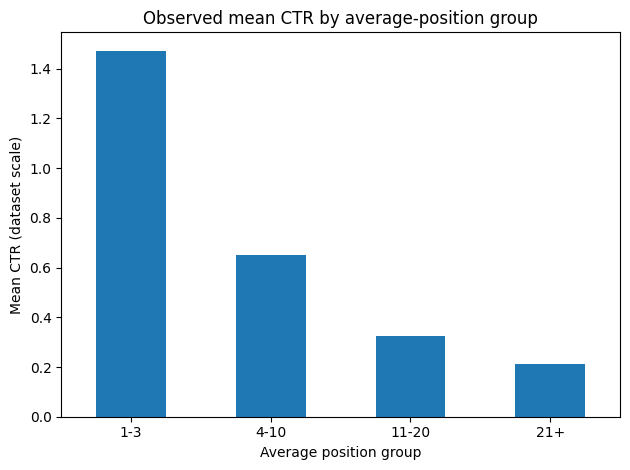

In [6]:
# Create position groups directly from avg_position; do not rely on a pre-existing bucket column.
assert "avg_position" in df.columns, "avg_position is required for this analysis."

eda = df.copy()
eda["avg_position_num"] = pd.to_numeric(eda["avg_position"], errors="coerce")
eda["ctr_num"] = pd.to_numeric(eda["ctr"], errors="coerce")
eda["position_group"] = pd.cut(
    eda["avg_position_num"],
    bins=[-np.inf, 3, 10, 20, np.inf],
    labels=["1-3", "4-10", "11-20", "21+"]
)

position_summary = (
    eda.dropna(subset=["position_group", "ctr_num"])
       .groupby("position_group", observed=False)
       .agg(
           rows=("ctr_num", "size"),
           mean_ctr=("ctr_num", "mean"),
           median_ctr=("ctr_num", "median")
       )
       .reset_index()
)
display(position_summary)

ax = position_summary.plot(
    kind="bar", x="position_group", y="mean_ctr", legend=False, rot=0
)
ax.set_xlabel("Average position group")
ax.set_ylabel("Mean CTR (dataset scale)")
ax.set_title("Observed mean CTR by average-position group")
plt.tight_layout()
plt.show()

Path("work/outputs").mkdir(parents=True, exist_ok=True)
position_summary.to_csv("work/outputs/position_ctr_summary.csv", index=False)


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*



## 5. Limitations

*What this work cannot claim.*

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
